In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [54]:
df=pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [56]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [57]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

### Train, test and validation sets

In [58]:
X=df.drop('Class', axis=1)
y=df['Class']

from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp=train_test_split(X, y, test_size=0.5, random_state=42, stratify=y)
X_val, X_test, y_val, y_test=train_test_split(X_temp, y_temp, test_size=0.6, random_state=42, stratify=y_temp)


In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [60]:
def calculate_profit(y_true, y_pred, amounts, fp_cost):
    profit = 0

    for actual, predicted, amount in zip(y_true, y_pred, amounts):

        if actual == 1 and predicted == 1:       
            profit += amount

        elif actual == 1 and predicted == 0:     
            profit -= amount

        elif actual == 0 and predicted == 1:     
            profit -= fp_cost

    return profit

In [61]:
def find_best_threshold(y_true, predicted_prob, amounts, fp_cost):

    best_profit=-np.inf
    best_threshold=None
    thresholds=np.arange(0.01, 1.00, 0.01)

    for threshold in thresholds:
        y_pred= (predicted_prob>=threshold).astype(int)

        profit=calculate_profit(y_true, y_pred, amounts, fp_cost)

        if(profit>best_profit):
            best_profit=profit
            best_threshold=threshold
    return best_profit, best_threshold


In [62]:

def profit_scorer(estimator, X, y):
    predicted_prob = estimator.predict_proba(X)[:, 1]
    amounts = X["Amount"].values

    best_profit, _ = find_best_threshold(
        y, predicted_prob, amounts, fp_cost=100
    )

    return best_profit


In [63]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [64]:
lr=LogisticRegression(class_weight="balanced", random_state=42)
lr.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [65]:
predicted_prob_lr=lr.predict_proba(X_val_scaled)[:, 1]

amount_val=X_val['Amount'].values
best_profit_lr, best_threshold_lr= find_best_threshold(y_val, predicted_prob_lr, amount_val, 100)
best_threshold_lr, best_profit_lr

(np.float64(0.99), np.float64(1341.640000000002))

In [66]:
from sklearn.metrics import confusion_matrix
y_pred_lr = (predicted_prob_lr >= best_threshold_lr).astype(int)
cm = confusion_matrix(y_val, y_pred_lr)

print(cm)

[[56813    50]
 [   19    79]]


In [67]:
tp_profit = 0
fn_loss = 0
fp_loss = 0

for actual, predicted, amount in zip(y_val, y_pred_lr, amount_val):

    if actual == 1 and predicted == 1:
        tp_profit += amount

    elif actual == 1 and predicted == 0:
        fn_loss += amount

    elif actual == 0 and predicted == 1:
        fp_loss += 100

print("TP profit:", tp_profit)
print("FN loss:", fn_loss)
print("FP loss:", fp_loss)
print("Net profit:", tp_profit - fn_loss - fp_loss)

TP profit: 11194.249999999998
FN loss: 4852.61
FP loss: 5000
Net profit: 1341.6399999999985


## 2. Random Forest

In [68]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [69]:
predicted_prob_rf = rf.predict_proba(X_val)[:, 1]

In [70]:
amount_val = X_val["Amount"].values

best_profit_rf, best_threshold_rf = find_best_threshold(
    y_val,
    predicted_prob_rf,
    amount_val,
    fp_cost=100
)

best_threshold_rf, best_profit_rf

(np.float64(0.23), np.float64(4984.379999999999))

## XGBoost

In [71]:
from xgboost import XGBClassifier
xgb = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)
xgb.fit(X_train, y_train)

predicted_prob_xgb=xgb.predict_proba(X_val)[:, 1]

amount_val = X_val["Amount"].values

best_profit_xgb, best_threshold_xgb = find_best_threshold(
    y_val,
    predicted_prob_xgb,
    amount_val,
    fp_cost=100
)

best_threshold_xgb, best_profit_xgb

(np.float64(0.01), np.float64(-16046.859999999995))

### *During hyperparameter tuning a threshold of 0.5 will be used for uniform evaluation of all models' performance and then each of those performances wil be optimized with the best hreshold for that model*

## Random Forest Hyperparameter tuning

In [ ]:

def fixed_threshold_profit_scorer(estimator, X, y):
    predicted_prob = estimator.predict_proba(X)[:, 1]
    y_pred = (predicted_prob >= 0.5).astype(int)
    amounts = X["Amount"].values

    return calculate_profit(y, y_pred, amounts, fp_cost=100)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV


In [73]:
rf_param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=rf_param_dist,
    n_iter=20,
    scoring=fixed_threshold_profit_scorer,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)


print("Best Parameters:", rf_search.best_params_)
print("Best Cross-Validation Profit:", rf_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}
Best Cross-Validation Profit: 4315.03


In [74]:
best_rf_params=rf_search.best_params_
best_rf= RandomForestClassifier(
    **best_rf_params,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

predicted_prob_rf_tuned = best_rf.predict_proba(X_val)[:, 1]

best_profit_rf_tuned, best_threshold_rf_tuned = find_best_threshold(
    y_val,
    predicted_prob_rf_tuned,
    X_val["Amount"].values,
    fp_cost=100
)
print("Best Validation Threshold:", best_threshold_rf_tuned)
print("Best Validation Profit:", best_profit_rf_tuned)

Best Validation Threshold: 0.14
Best Validation Profit: 5440.119999999999


## XGBoost Hyperparameter tuning

In [75]:
def fixed_threshold_profit_scorer(estimator, X, y):
    predicted_prob = estimator.predict_proba(X)[:, 1]
    y_pred = (predicted_prob >= 0.5).astype(int)
    amounts = X["Amount"].values

    return calculate_profit(y, y_pred, amounts, fp_cost=100)

In [76]:
xgb_param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, 10],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "scale_pos_weight": [1, 10, 50, 100]
}


In [77]:
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ),
    param_distributions=xgb_param_dist,
    n_iter=20,
    scoring=fixed_threshold_profit_scorer,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
xgb_search.fit(X_train, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best Cross-Validation Profit:", xgb_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'subsample': 0.9, 'scale_pos_weight': 1, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best Cross-Validation Profit: 5166.343333333333


In [78]:
best_xgb_params = xgb_search.best_params_

best_xgb = XGBClassifier(
    **best_xgb_params,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

best_xgb.fit(X_train, y_train)

predicted_prob_xgb_tuned = best_xgb.predict_proba(X_val)[:, 1]

best_profit_xgb_tuned, best_threshold_xgb_tuned = find_best_threshold(
    y_val,
    predicted_prob_xgb_tuned,
    X_val["Amount"].values,
    fp_cost=100
)

print("Best Validation Threshold:", best_threshold_xgb_tuned)
print("Best Validation Profit:", best_profit_xgb_tuned)

Best Validation Threshold: 0.14
Best Validation Profit: 4610.199999999999


## Logistic Regressiion Hyperparameter tuning

In [79]:
def fixed_threshold_profit_scorer(estimator, X, y):
    predicted_prob = estimator.predict_proba(X)[:, 1]

    y_pred = (predicted_prob >= 0.5).astype(int)
    amounts = X["Amount"].values

    return calculate_profit(y, y_pred, amounts, fp_cost=100)

from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        random_state=42,
        max_iter=2000
    ))
])

In [80]:
lr_param_dist = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "liblinear"],
    "model__class_weight": ["balanced", None]
}

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_param_dist,
    n_iter=20,
    scoring=fixed_threshold_profit_scorer,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lr_search.fit(X_train, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best Cross-Validation Profit:", lr_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'model__solver': 'liblinear', 'model__class_weight': None, 'model__C': 100}
Best Cross-Validation Profit: 434.74333333333317


In [82]:
best_lr_params = lr_search.best_params_

best_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        random_state=42,
        max_iter=2000
    ))
])

best_lr.set_params(**best_lr_params)

best_lr.fit(X_train, y_train)

predicted_prob_lr_tuned = best_lr.predict_proba(X_val)[:, 1]

best_profit_lr_tuned, best_threshold_lr_tuned = find_best_threshold(
    y_val,
    predicted_prob_lr_tuned,
    X_val["Amount"].values,
    fp_cost=100
)

print("Best Validation Threshold:", best_threshold_lr_tuned)
print("Best Validation Profit:", best_profit_lr_tuned)

Best Validation Threshold: 0.02
Best Validation Profit: 1065.7799999999995


## Testing 3 best models on test data

In [83]:
predicted_prob_lr_test = best_lr.predict_proba(X_test)[:, 1]
predicted_prob_rf_test = best_rf.predict_proba(X_test)[:, 1]
predicted_prob_xgb_test = best_xgb.predict_proba(X_test)[:, 1]

y_pred_lr_test = (predicted_prob_lr_test >= best_threshold_lr_tuned).astype(int)
y_pred_rf_test = (predicted_prob_rf_test >= best_threshold_rf_tuned).astype(int)
y_pred_xgb_test = (predicted_prob_xgb_test >= best_threshold_xgb_tuned).astype(int)

test_profit_lr = calculate_profit(
    y_test, y_pred_lr_test, X_test["Amount"].values, fp_cost=100
)

test_profit_rf = calculate_profit(
    y_test, y_pred_rf_test, X_test["Amount"].values, fp_cost=100
)

test_profit_xgb = calculate_profit(
    y_test, y_pred_xgb_test, X_test["Amount"].values, fp_cost=100
)

print("LR Test Profit:", test_profit_lr)
print("RF Test Profit:", test_profit_rf)
print("XGBoost Test Profit:", test_profit_xgb)


LR Test Profit: -3278.820000000001
RF Test Profit: 4634.08
XGBoost Test Profit: 6013.299999999998


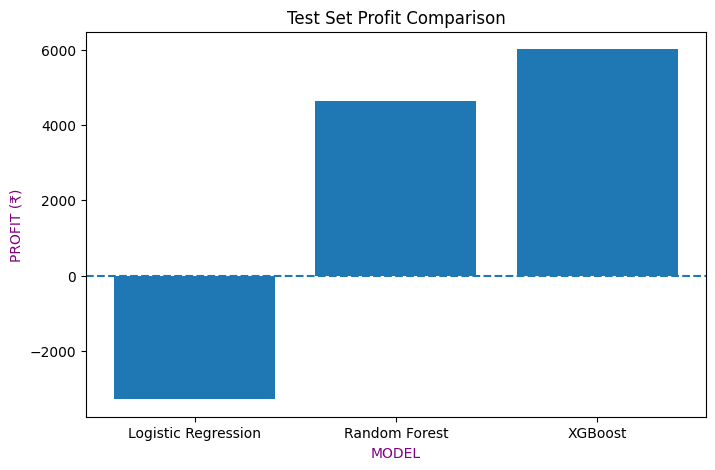

In [88]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Logistic Regression", "Random Forest", "XGBoost"],
    [test_profit_lr, test_profit_rf, test_profit_xgb]
)

ax.set_title("Test Set Profit Comparison")
ax.set_xlabel("MODEL", c='purple')
ax.set_ylabel("PROFIT (₹)", c='purple')
ax.axhline(y=0, linestyle="--")